# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Nithya Gopal, Jacob Khaykin, Heidi Williams

**Date:** 11/09/2026

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

houses = pd.read_csv("data/pierce_county_house_sales.csv")
print("Original shape:", houses.shape)
display(houses.dtypes)
display(houses.isna().sum())
print("Duplicate rows:", houses.duplicated().sum())

houses = houses.drop_duplicates().copy()
houses["sale_date"] = pd.to_datetime(houses["sale_date"])
category_columns = houses.select_dtypes(include=["object", "string"]).columns
houses[category_columns] = houses[category_columns].fillna("Unknown")
print("Cleaned shape:", houses.shape)
print("Remaining missing values:", houses.isna().sum().sum())

Original shape: (16814, 19)


sale_date                        str
sale_price                     int64
house_square_feet              int64
attic_finished_square_feet     int64
basement_square_feet           int64
attached_garage_square_feet    int64
detached_garage_square_feet    int64
fireplaces                     int64
hvac_description                 str
exterior                         str
interior                         str
stories                        int64
roof_cover                       str
year_built                     int64
bedrooms                       int64
bathrooms                      int64
waterfront_type                  str
view_quality                     str
utility_sewer                    str
dtype: object

sale_date                          0
sale_price                         0
house_square_feet                  0
attic_finished_square_feet         0
basement_square_feet               0
attached_garage_square_feet        0
detached_garage_square_feet        0
fireplaces                         0
hvac_description                   7
exterior                           1
interior                           7
stories                            0
roof_cover                         8
year_built                         0
bedrooms                           0
bathrooms                          0
waterfront_type                16261
view_quality                   15895
utility_sewer                      0
dtype: int64

Duplicate rows: 46
Cleaned shape: (16768, 19)
Remaining missing values: 0


,sale_price,house_square_feet,bedrooms,bathrooms
count,1.676800e+04,16768.000000,16768.000000,16768.000000
mean,4.612053e+05,1879.174082,3.276419,2.316078
std,2.361158e+05,760.438267,0.891160,0.828058
min,2.000000e+03,1.000000,0.000000,0.000000
25%,3.480000e+05,1320.000000,3.000000,2.000000
50%,4.167250e+05,1774.000000,3.000000,2.000000
75%,5.238815e+05,2351.250000,4.000000,3.000000
max,6.130000e+06,9510.000000,25.000000,8.000000


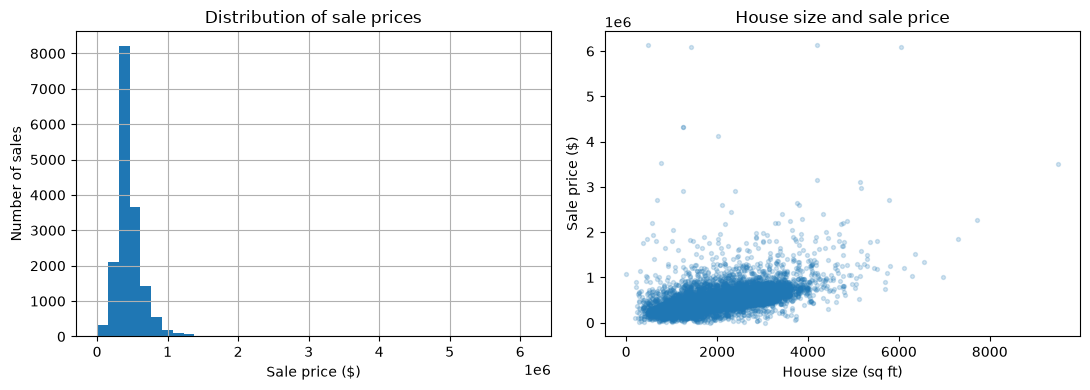

In [2]:
display(houses[["sale_price", "house_square_feet", "bedrooms", "bathrooms"]].describe())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
houses["sale_price"].hist(bins=40, ax=axes[0])
axes[0].set(title="Distribution of sale prices", xlabel="Sale price ($)", ylabel="Number of sales")
axes[1].scatter(houses["house_square_feet"], houses["sale_price"], alpha=0.2, s=8)
axes[1].set(title="House size and sale price", xlabel="House size (sq ft)", ylabel="Sale price ($)")
plt.tight_layout()
plt.show()

As seen by the distribution above, sale prices are skewed to the right. Furthermore, larger houses generally sell for more.

In [3]:
X = pd.get_dummies(
    houses.drop(columns=["sale_price", "sale_date"]),
    columns=category_columns,
    drop_first=True,
    dtype=int,
)
y = houses["sale_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=112
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Features:", X_train.shape[1])

Training rows: 13414
Test rows: 3354
Features: 59


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [4]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]